In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
EF_GAS, EF_COAL = 0.202, 0.341
EFF_GAS, EFF_COAL = 0.51, 0.35

In [3]:
spreads = pd.read_csv("../3_Compute/eu_spreads.csv", index_col="date", parse_dates=True)
spreads = spreads.rename(columns={
    "EU_Clean_Spark_Spread": "Gas",
    "EU_Clean_Dark_Spread": "Coal",
    "EU_Clean_Gasoil_Spread": "Oil",
})

fwd = pd.read_csv("../2_Transform/transformed_forwards.csv", index_col="date", parse_dates=True)

In [4]:
def clean_spread(power, fuel, co2, eff, ef):
    return power - (fuel + ef * co2) / eff

spark_m2 = clean_spread(fwd["DE_POWER_M2"], fwd["TTF_GAS_M2"], fwd["EUA_M2"], EFF_GAS, EF_GAS)
dark_m2 = clean_spread(fwd["DE_POWER_M2"], fwd["COAL_M2"], fwd["EUA_M2"], EFF_COAL, EF_COAL)

In [6]:
cheapest = spreads.idxmax(axis=1)
pd.crosstab(cheapest.index.year, cheapest, rownames=["Year"], colnames=["Cheapest fuel (days)"]).reindex(columns=["Gas", "Coal", "Oil"], fill_value=0)

Cheapest fuel (days),Gas,Coal,Oil
Year,,,
2019,249,11,0
2020,262,0,0
2021,148,113,0
2022,15,245,0
2023,214,46,0
2024,227,35,0
2025,190,70,0
2026,60,163,0


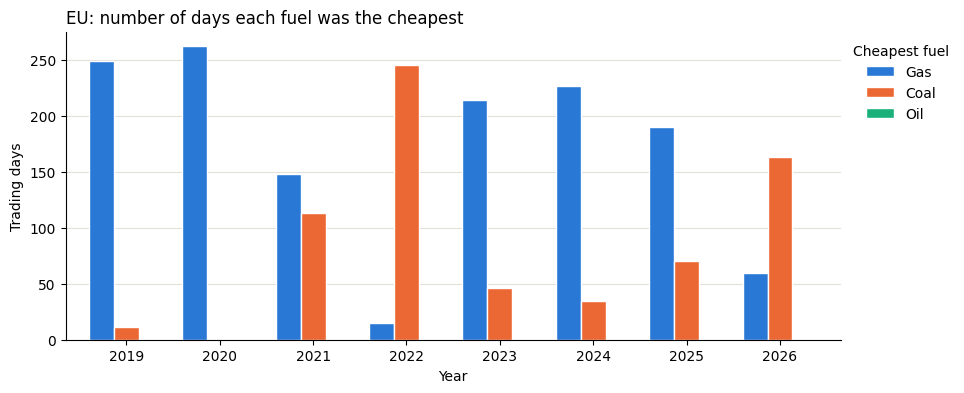

In [13]:
table = pd.crosstab(cheapest.index.year, cheapest).reindex(columns=["Gas", "Coal", "Oil"], fill_value=0)

ax = table.plot(
    kind="bar", stacked=False, figsize=(10, 4), width=0.8,
    color=[COLORS["Gas"], COLORS["Coal"], COLORS["Oil"]], edgecolor="white", linewidth=1,
)
ax.set_xlabel("Year")
ax.set_ylabel("Trading days")
ax.set_title("EU: number of days each fuel was the cheapest", loc="left")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="x", visible=False)
ax.legend(title="Cheapest fuel", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

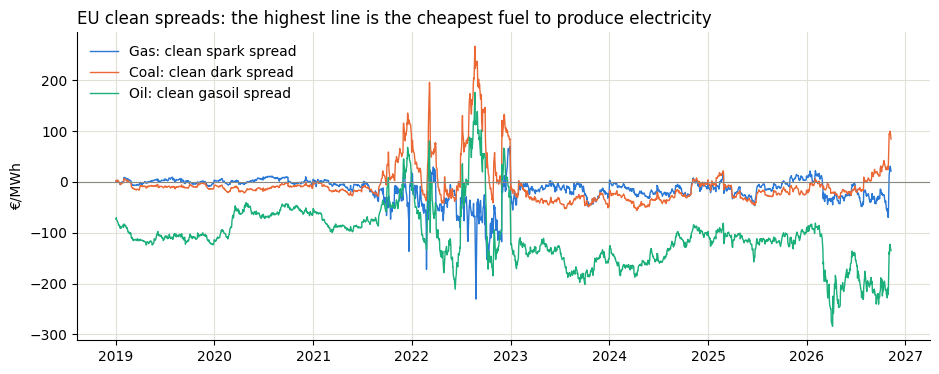

In [9]:
labels = {"Gas": "Gas: clean spark spread", "Coal": "Coal: clean dark spread", "Oil": "Oil: clean gasoil spread"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "legend.frameon": False})
COLORS = {"Gas": "#2a78d6", "Coal": "#eb6834", "Oil": "#1baf7a"}

fig, ax = plt.subplots(figsize=(11, 4))
for fuel in ["Gas", "Coal", "Oil"]:
    ax.plot(spreads.index, spreads[fuel], color=COLORS[fuel], lw=1, label=labels[fuel])
ax.axhline(0, color="#898781", lw=0.8)
ax.set_ylabel("€/MWh")
ax.set_title("EU clean spreads: the highest line is the cheapest fuel to produce electricity", loc="left")
ax.legend(loc="upper left")
plt.show()